<a href="https://colab.research.google.com/github/sailesh5896/dl-cat-II/blob/main/Crypto_currency_price_history.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("coin_Bitcoin.csv")
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
df = df.dropna(subset=["Date", "Close"]).sort_values("Date")
df = df.drop_duplicates(subset=["Date"]).tail(2000).reset_index(drop=True)
df["Close"] = df["Close"].interpolate().ffill().bfill()

split = int(len(df) * 0.8)
scaler = MinMaxScaler()
scaler.fit(df[["Close"]].iloc[:split])
scaled = scaler.transform(df[["Close"]])

X, y = [], []
for i in range(7, len(scaled)):
    X.append(scaled[i-7:i, 0])
    y.append(scaled[i, 0])

X = np.array(X).reshape(-1, 7, 1)
y = np.array(y)
X_train, X_test = X[:split-7], X[split-7:]
y_train, y_test = y[:split-7], y[split-7:]

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isnull().sum().sum())
print("Sliding Window: Previous 7 Days")
print("Total Sequences:", len(X))
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)
print("Normalization: MinMaxScaler")

Dataset Shape: (2000, 10)
Missing Values: 0
Sliding Window: Previous 7 Days
Total Sequences: 1993
Training Shape: (1593, 7, 1)
Testing Shape: (400, 7, 1)
Normalization: MinMaxScaler


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_4 (GRU)                     │ (None, 50)             │         7,950 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,251 (36.14 KB)

 Trainable params: 9,251 (36.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0114 - val_loss: 0.0012
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0080 - val_loss: 0.0018
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0012 - val_loss: 7.6628e-04
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.8175e-04 - val_loss: 5.7869e-04
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5.4464e-04 - val_loss: 5.8257e-04
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 5.6200e-04 - val_loss: 5.8889e-04
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5.6299e-04 - val_loss: 6.0163e-04
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 5.7325e-04 - val_loss: 6.3038e-04
Epoch 9/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 5.7905e-04 - val_loss: 6.5079e-04
Epoch 10/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 5.9633e-04 - val_loss: 7.0860e-04
Epoch 11/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 6.1133e-04 - val_loss: 7.4142e-04
Epo

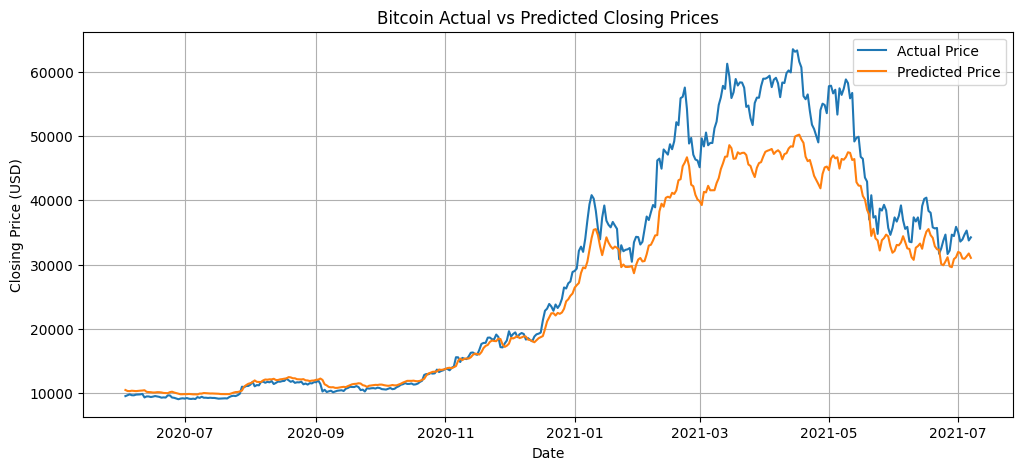

Last 7 Closing Prices: [35040.83724889, 33572.11765253, 33897.04858963, 34668.54840182, 35287.77976616, 33746.00245614, 34235.19345116]
Predicted Next-Day Closing Price (USD): 31094.47


In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(7, 1)),
    tf.keras.layers.GRU(50),
    tf.keras.layers.Dense(25, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer="adam", loss="mse")
model.summary()

model.fit(X_train, y_train, epochs=30, batch_size=32, validation_split=0.1, shuffle=False, verbose=1)

predicted = scaler.inverse_transform(model.predict(X_test, verbose=0))
actual = scaler.inverse_transform(y_test.reshape(-1, 1))

print("MAE:", round(mean_absolute_error(actual, predicted), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 2))

plt.figure(figsize=(12, 5))
plt.plot(df["Date"].iloc[split:], actual, label="Actual Price")
plt.plot(df["Date"].iloc[split:], predicted, label="Predicted Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.title("Bitcoin Actual vs Predicted Closing Prices")
plt.legend()
plt.grid(True)
plt.show()

last_7 = scaler.transform(df[["Close"]].tail(7)).reshape(1, 7, 1)
next_price = scaler.inverse_transform(model.predict(last_7, verbose=0))[0, 0]
print("Last 7 Closing Prices:", df["Close"].tail(7).to_list())

print("Predicted Next-Day Closing Price (USD):", round(float(next_price), 2))